In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("Student_Smart_Assistant_Dataset.csv")

# Create Total Digital Distraction
df["digital_distraction_hours"] = (
    df["social_media_hours"] +
    df["youtube_hours"] +
    df["gaming_hours"] +
    df["phone_usage_hours"]
)

# Create Productivity Category
df["productivity_category"] = pd.cut(
    df["productivity_score"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

# Create Study Category
df["study_category"] = pd.cut(
    df["study_hours_per_day"],
    bins=[-np.inf, 4, 7, np.inf],
    labels=["Low Study", "Moderate Study", "High Study"]
)

# Create Distraction Level
df["distraction_level"] = pd.cut(
    df["digital_distraction_hours"],
    bins=[-np.inf, 10, 20, np.inf],
    labels=["Low", "Medium", "High"]
)

# Create Sleep Category
df["sleep_category"] = pd.cut(
    df["sleep_hours"],
    bins=[-np.inf, 5, 7, np.inf],
    labels=["Low Sleep", "Normal Sleep", "High Sleep"]
)

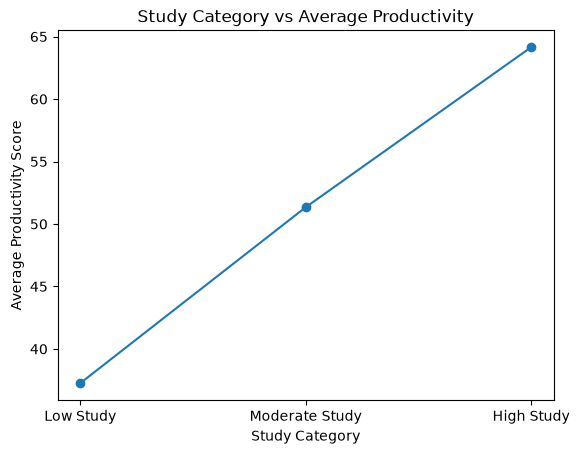

In [2]:
import matplotlib.pyplot as plt

study_productivity = df.groupby(
    "study_category",
    observed=True
)["productivity_score"].mean()

plt.plot(
    study_productivity.index,
    study_productivity.values,
    marker="o"
)

plt.title("Study Category vs Average Productivity")
plt.xlabel("Study Category")
plt.ylabel("Average Productivity Score")

plt.show()

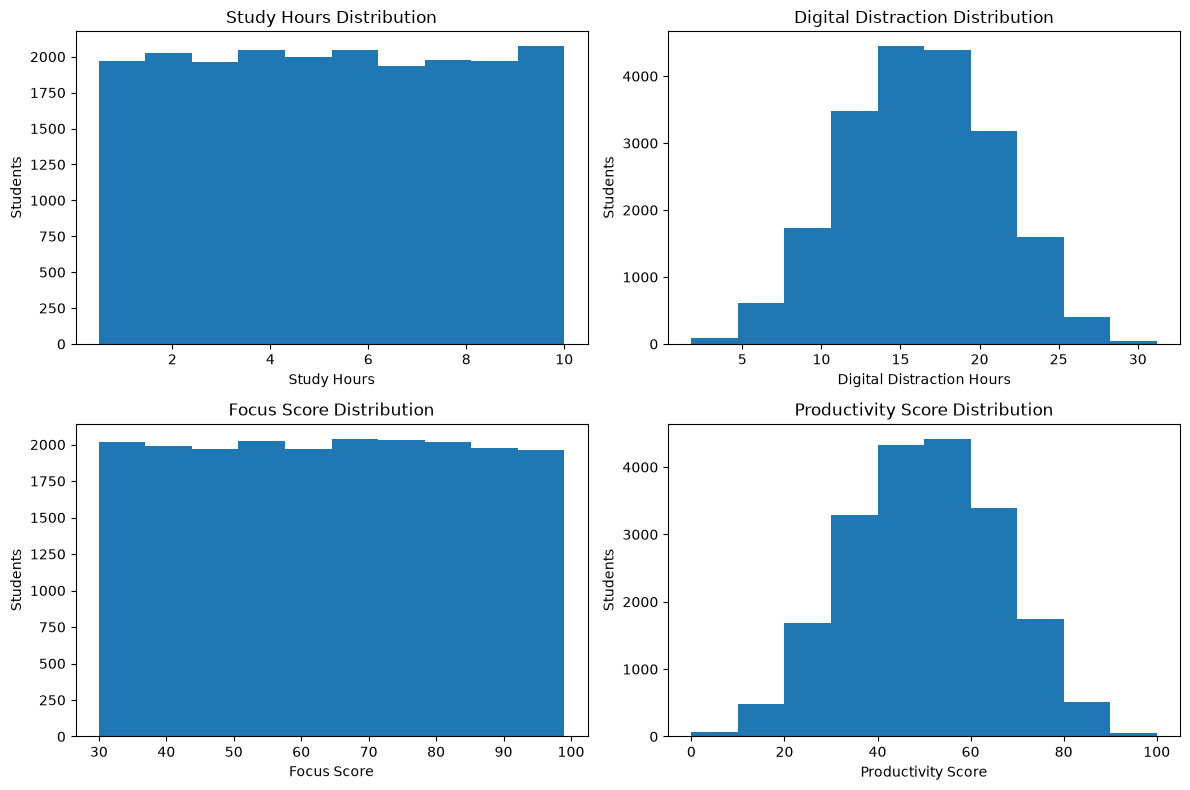

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Study Hours
axes[0, 0].hist(
    df["study_hours_per_day"],
    bins=10
)
axes[0, 0].set_title("Study Hours Distribution")
axes[0, 0].set_xlabel("Study Hours")
axes[0, 0].set_ylabel("Students")


# 2. Digital Distraction
axes[0, 1].hist(
    df["digital_distraction_hours"],
    bins=10
)
axes[0, 1].set_title("Digital Distraction Distribution")
axes[0, 1].set_xlabel("Digital Distraction Hours")
axes[0, 1].set_ylabel("Students")


# 3. Focus Score
axes[1, 0].hist(
    df["focus_score"],
    bins=10
)
axes[1, 0].set_title("Focus Score Distribution")
axes[1, 0].set_xlabel("Focus Score")
axes[1, 0].set_ylabel("Students")


# 4. Productivity Score
axes[1, 1].hist(
    df["productivity_score"],
    bins=10
)
axes[1, 1].set_title("Productivity Score Distribution")
axes[1, 1].set_xlabel("Productivity Score")
axes[1, 1].set_ylabel("Students")

plt.tight_layout()

plt.show()